In [1]:
#0. 필요한 모듈 사용
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

In [2]:
#1. GPU 사용환경 준비
device= torch.device('cuda' if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [3]:
#2. CIFAR-10 데이터셋 다운로드하고 파이토치 모델에서 사용하기 위해 전처리

# 기본 전처리를 위한 파이프라인
transforms= transforms.Compose([
    #1) 텐서 데이터로 변환
    transforms.ToTensor(),  # PIL 이미지나 numpy배열을 파이토치 Tensor로 변환. [0,255]-->[0.0, 1.0]사이의 실수로 변환. (Height, Width, Channel) --> (C,H,W) 로 차원의 순서를 변환. 이 3개의 역할을 해주는게 ToTensor
    #2) 정규화 (표준화 Z-Score) ~~ [0.0, 1.0]범위였던 픽셀값들이 [-1.0, 1.0] 범위로 변환
    transforms.Normalize((0.5, 0.5, 0.5),(0.5, 0.5, 0.5))  #평균값, 표준편차값을 지정 (R,G,B)
    # X-Score = (x - 평균) / 표준편차
])

#1) 훈련용 데이터 다운로드
train_dataset= datasets.CIFAR10(
    root= './data',  #다운로드할 경로
    train= True,
    download= True,
    transform= transforms  #위 전처리 파이프라인 함수를 사용하여 데이터를 전처리
)

#2) 테스트용 데이터 다운로드
test_dataset= datasets.CIFAR10(
    root= './data',
    train= False,
    download= True,
    transform= transforms
)

100%|██████████| 170M/170M [35:49<00:00, 79.3kB/s]


In [4]:
#3. 데이터 확인
print('훈련용 데이터 개수:', len(train_dataset))
print('테스트용 데이터 개수:', len(test_dataset))

훈련용 데이터 개수: 50000
테스트용 데이터 개수: 10000


분류(클래스)명: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


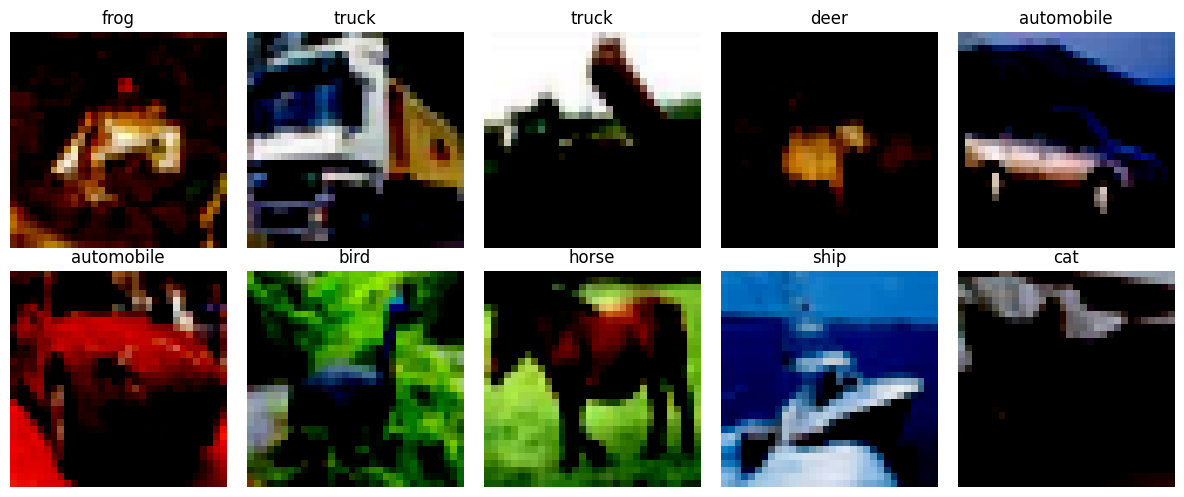

In [5]:
#4. [데이터 중 리부를 시각화 - 이미지 샘플 보기]

# CIFAR DataSet의 클래스 이름들 준비
class_names= train_dataset.classes
print('분류(클래스)명:', class_names)

# 이미지 샘플 10개를 시각화 (서브플롯이 10개. 2행 5열)
fig, axes= plt.subplots(2, 5, figsize=(12, 5))

for idx, ax in enumerate(axes.flat):
  image, label= train_dataset[idx]  #0~9번까지의 이미지와 라벨값

  # matplotlib 은 이미지가 [Height, Width, Channel] 순으로 되어있어야 올바르게 그려줌
  # dataset은 transforms에 의해 [C,H,W] 순으로 되어있음. 이 차원의 순서를 변환
  image= image.permute(1,2,0)  #원래이미지의 1번방을 0번방으로, 2번방을 1번방으로, 0번방을 3번방으로 변환...

  ax.imshow(image)
  ax.set_title(class_names[label])
  ax.axis('off')

plt.tight_layout()
plt.show()

In [6]:
#5. 데이터셋을 효율적으로 학습하기 위해 미니배치 형태로 묶고 관리해주는 DataLoader를 생성
# 1) 훈련용 데이터셋 로더 생성
train_loader= DataLoader(
    train_dataset,
    batch_size= 128,
    shuffle= True,
    num_workers= 2,     #데이터를 불러오고 전처리 할 때 사용한 서브프로세스의 개수 지정. 병렬처리
)

# 2) 테스트용 데이터셋 로더 생성
test_loader= DataLoader(
    test_dataset,
    batch_size= 128,
    shuffle= False,
    num_workers= 2,
)

In [7]:
#6. 모델 설계
# 1) 초기화 영역에서 할 일 : 신경망의 구성요소를 멤버로 만들기
# 2) forward 메소드에서 할 일 : 신경망의 구성요소를 파이프라인처럼 연결하고 결과를 리턴.
class CifarCNN(nn.Module):
  def __init__(self):
    super().__init__()

    #1) 특성 추출기
    self.features= nn.Sequential(
        #Conv1 -- 비교적 단순한 선, 면, 곡선 등의 에지검출..
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),   # activation function
        nn.MaxPool2d(2),  # pooling layer - 32*32 ==> 16*16

        #Conv2 -- 조금 더 복잡한 특징 찾아내는 층 -- 형태 비스므리 하게 나오는...
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),   # activation function
        nn.MaxPool2d(2),  # pooling layer - 16*16 ==> 8*8

        #Conv3 -- 최종형태가 보이는 특징 찾아내는 층 -- 형태가 보이는..
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),   # activation function
        nn.MaxPool2d(2)  # pooling layer - 8*8 ==> 4*4
    )

    #2) 분류기
    self.classifier= nn.Sequential(
        # 3차원의 특성맵을 1차원의 배열로 변환
        nn.Flatten(),   # 128*4*4 개 만큼의 배열길이

        # 펼쳐진 데이터를 입력으로 받아, 256개의 뉴런 출력으로 만들어.. 픽셀간의 관계를 선형학습 (즉, 독립변수가 2,048개)
        nn.Linear(128*4*4, 256),  # FC layer (FC: Fully Connect)
        nn.ReLU(), #활성화 함수
        nn.Dropout(0.4),  #학습할때 256개의 특징을 모두 사용하지 않고 0.4(40%)의 확률로 무작위 추출하여 0으로 만들어 과적합(overfitting)을 방지

        #최종 10개의 분류종류로 다중분류
        nn.Linear(256, 10)
    )
  #---------------------------- init -------------------------

  def forward(self, x):
    #특성추출기에 통과
    x= self.features(x)
    #특성맵을 분류기에 넣고 결과 리턴
    return self.classifier(x)

In [8]:
#7. 모델생성 및 GPU로 이동
model= CifarCNN().to(device)

In [9]:
#8. 손실함수와 최적화
criterion= nn.CrossEntropyLoss()  #다중분류
optimizer= optim.Adam(model.parameters(), lr= 0.001)

In [10]:
#9. 모델 학습시키기
epochs= 5
for epoch in range(epochs):
  model.train()  #훈련모드

  #에포크 마다 손실값, 정확도 저장용 변수
  epoch_loss= 0
  epoch_accuracy= 0

  #이미지를 한장씩이 아니라 미니배치 단위로 묶어서 주는 로더를 이용하여 모든 데이터 학습
  for images, labels in train_loader:
    #데이터를 GPU로 이동
    images= images.to(device)
    labels= labels.to(device)

    # 기울기 초기화
    optimizer.zero_grad()

    #128개의 이미지 묶음(미니배치)에 대한 클래스별 확률값을 모델에게 요청
    outputs= model(images)

    #모델의 오차를 계산(실제값-예측값)
    loss= criterion(outputs, labels)

    #오차를 기반으로 출력층부터.. 반대로 올라오면서 오차가 작아지도록 기울기를 새로 계산(자동미분) -- 역전파
    loss.backward()

    #계산된 새로운 기울기로 업데이트
    optimizer.step()

    #손실값 확인을 위해.. 손실값 누적
    epoch_loss += loss.item()

    #정확도 계산
    _, predictions= outputs.max(dim=1)
    epoch_accuracy += ( predictions == labels ).sum().item()
  #---------------------------------------------------------------
  #맞춘 개수를 총 데이터수로 나누기
  accuracy= (epoch_accuracy / len(train_dataset) * 100)
  print(f"{epoch}에포크: 손실 - {epoch_loss:.4f} // 정확도 - {accuracy:.2f}%")

0에포크: 손실 - 599.8651 // 정확도 - 43.83%
1에포크: 손실 - 450.6600 // 정확도 - 58.57%
2에포크: 손실 - 378.7008 // 정확도 - 65.42%
3에포크: 손실 - 329.0470 // 정확도 - 70.38%
4에포크: 손실 - 292.2568 // 정확도 - 73.64%


In [10]:
# 모델의 성능을 개선하는 방법 중 하나인, 데이터셋의 크기를 증가시키는 방안.
# 원본데이터를 --> 좌우반전 / 일부영역 잘라내기/위치이동 들을 증강시킬 수 있음.
# Data Augmentation

# 데이터 전처리에 사용했던 모듈 transforms
transforms= transforms.Compose([
    #1) 데이터 증강용 구성요소
    transforms.RandomHorizontalFlip(),  #좌우반전
    transforms.RandomCrop(32, padding=4),  #이미지 주변에 여백추가 후 랜덤하게 일부영역을 추출

    transforms.ToTensor(),

    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),  #학습용 데이터셋의 평균 -- 검색하면 알 수 있음. cifar-10
        (0.2470, 0.2435, 0.2616),  #학습용 데이터셋의 표준데이터
    )
])